# ПР №4 — Линейная регрессия, уровень B

Данные: встроенный **Diabetes regression** scikit-learn; целевая переменная `progression_score` — количественная оценка прогрессирования заболевания, а не денежная сумма. Это иллюстрация статистического метода, а не медицинский прогноз для применения в жизни.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
FIG=Path('../figures');FIG.mkdir(exist_ok=True)
df=pd.read_csv('../data/diabetes.csv')
X=df.drop(columns='progression_score');y=df['progression_score']
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42)
print('Обучающая выборка:',Xtr.shape,'Тест:',Xte.shape)
print('Числовые признаки:',X.columns.to_list())

Обучающая выборка: (353, 10) Тест: (89, 10)
Числовые признаки: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## Проверка мультиколлинеарности

Матрица строится **на train**. При `|r| ≥ 0.80` один из двух сильно связанных признаков можно удалить. Мы применим простой последовательный критерий, проверим метрики и не будем считать корреляцию причинностью.

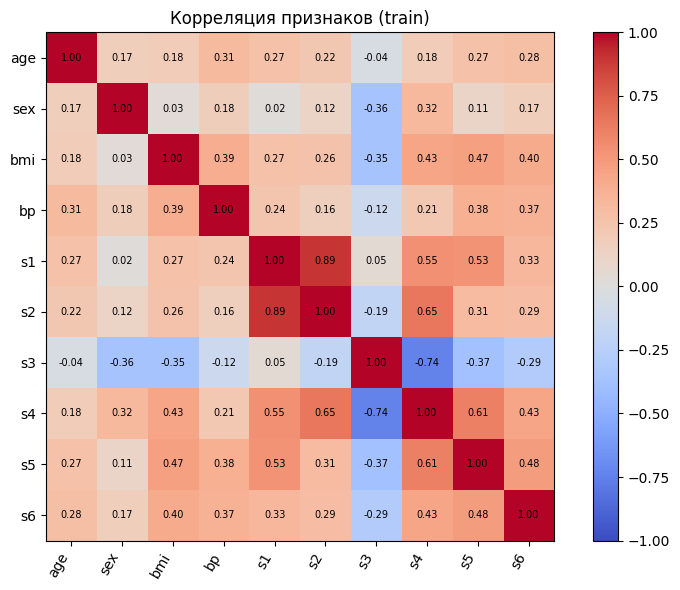

Исключены: ['s2'] 
Оставлены: ['age', 'sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']


In [2]:
corr=Xtr.corr()
fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right');ax.set_yticks(range(len(corr)),corr.columns)
for a in range(len(corr)):
    for b in range(len(corr)):ax.text(b,a,f'{corr.iloc[a,b]:.2f}',ha='center',va='center',fontsize=7)
fig.colorbar(im,ax=ax);ax.set_title('Корреляция признаков (train)')
fig.tight_layout();fig.savefig(FIG/'correlation.png',dpi=120);plt.show()
removed=[];selected=[]
for column in Xtr.columns:
    if any(abs(corr.loc[column,kept])>=.80 for kept in selected):removed.append(column)
    else:selected.append(column)
print('Исключены:',removed,'\nОставлены:',selected)

## Модели: все признаки и сокращённый набор

Одинаковое разбиение и одинаковая предобработка: `SimpleImputer(median) → StandardScaler → LinearRegression`. Тест нигде не используется для настройки коэффициентов.

In [3]:
def fit_model(features):
    model=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('lr',LinearRegression())])
    model.fit(Xtr[features],ytr)
    pred=model.predict(Xte[features])
    return model,pred,{'MAE':mean_absolute_error(yte,pred),'RMSE':np.sqrt(mean_squared_error(yte,pred)),'R2':r2_score(yte,pred)}
base,base_pred,base_met=fit_model(X.columns.tolist())
small,small_pred,small_met=fit_model(selected)
metrics=pd.DataFrame([{'model':'Все числовые',**base_met},{'model':'Без сильной корреляции',**small_met}])
display(metrics.round(3))
Path('../reports').mkdir(exist_ok=True)
metrics.to_csv('../reports/metrics.csv',index=False)

,model,MAE,RMSE,R2
0,Все числовые,42.794,53.853,0.453
1,Без сильной корреляции,42.880,53.854,0.453


## График остатков

Случайно разбросанные остатки вокруг нуля лучше согласуются с линейными предположениями. Отчёт о систематическом паттерне — интерпретация изображения, не строгий статистический тест.

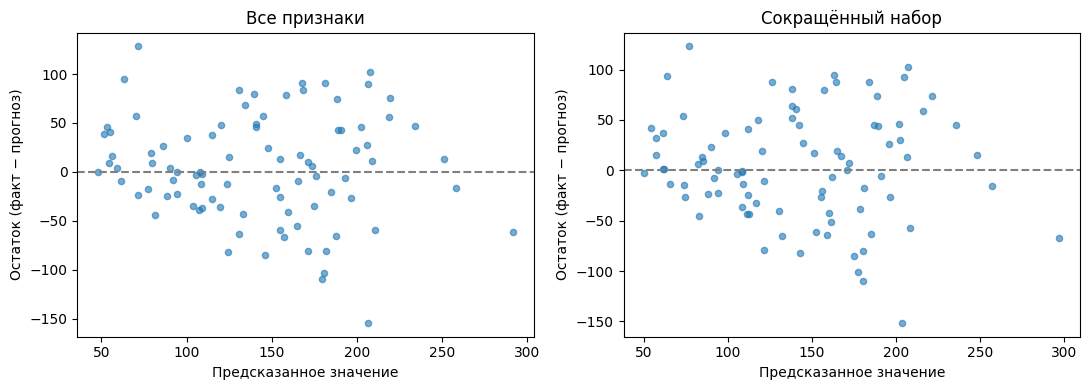

,feature,coef_standardized
4,s1,-44.449
8,s5,35.161
2,bmi,25.607
5,s2,24.641
3,bp,16.829
7,s4,13.139


In [4]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,pred,name in zip(axs,[base_pred,small_pred],['Все признаки','Сокращённый набор']):
    residual=np.asarray(yte)-pred
    ax.scatter(pred,residual,alpha=.6,s=20);ax.axhline(0,ls='--',color='gray')
    ax.set(title=name,xlabel='Предсказанное значение',ylabel='Остаток (факт − прогноз)')
fig.tight_layout();fig.savefig(FIG/'residuals.png',dpi=130);plt.show()
coef=pd.DataFrame({'feature':X.columns,'coef_standardized':base.named_steps['lr'].coef_}).sort_values('coef_standardized',key=lambda a:a.abs(),ascending=False)
display(coef.head(6).round(3))

## Обоснование выбора финальной модели

In [5]:
from sklearn.model_selection import cross_val_score, KFold
# Выбираем вариант по кросс-валидации ТОЛЬКО на train, не по тестовым метрикам.
def cv_mae(features):
    candidate=Pipeline([('imputer',SimpleImputer(strategy='median')),
                        ('scale',StandardScaler()),('lr',LinearRegression())])
    scores=-cross_val_score(candidate,Xtr[features],ytr,
                            scoring='neg_mean_absolute_error',
                            cv=KFold(n_splits=5,shuffle=True,random_state=42))
    return float(scores.mean())
cv_all=cv_mae(X.columns.tolist())
cv_small=cv_mae(selected)
print(f'Средний MAE по CV на train: все = {cv_all:.2f}, сокращённые = {cv_small:.2f}')
if cv_small<=cv_all+1:
    final='сокращённую модель'
    rationale='По CV ухудшение MAE меньше 1 балла или его нет, а признаков меньше.'
else:
    final='базовую модель'
    rationale='По CV ухудшение MAE от удаления признаков больше 1 балла.'
print('Финальный выбор по CV:',final,'.',rationale)
print(f'Тестовые метрики всех признаков: MAE={base_met["MAE"]:.2f}, RMSE={base_met["RMSE"]:.2f}, R²={base_met["R2"]:.3f}.')
print(f'Тестовые метрики сокращённой модели: MAE={small_met["MAE"]:.2f}, RMSE={small_met["RMSE"]:.2f}, R²={small_met["R2"]:.3f}.')
print('MAE и RMSE выражены в единицах шкалы progression_score, а не процентах.')

Средний MAE по CV на train: все = 45.05, сокращённые = 45.03
Финальный выбор по CV: сокращённую модель . По CV ухудшение MAE меньше 1 балла или его нет, а признаков меньше.
Тестовые метрики всех признаков: MAE=42.79, RMSE=53.85, R²=0.453.
Тестовые метрики сокращённой модели: MAE=42.88, RMSE=53.85, R²=0.453.
MAE и RMSE выражены в единицах шкалы progression_score, а не процентах.
